# Basic Image Analytics


In [7]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import json

DATASET = Path("../dataset/NEU-DET")
OUTPUT = Path("../outputs/neu_basic_analytics")
OUTPUT.mkdir(parents=True, exist_ok=True)
sample_path = sorted((DATASET / "train/images/crazing").glob("*.jpg"))[0]
image_bgr = cv2.imread(str(sample_path))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)


# Image Representation and Color Models


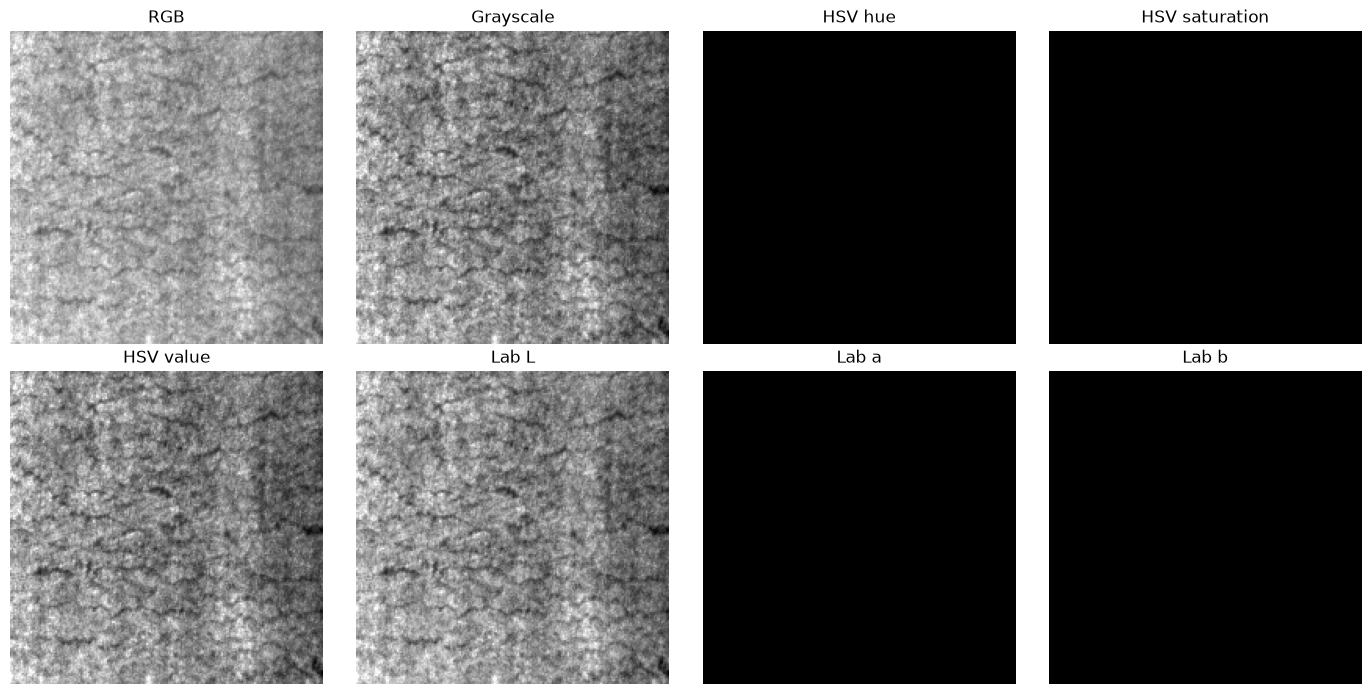

In [3]:
hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
images = [image_rgb, gray, hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2], lab[:, :, 0], lab[:, :, 1], lab[:, :, 2]]
titles = ["RGB", "Grayscale", "HSV hue", "HSV saturation", "HSV value", "Lab L", "Lab a", "Lab b"]
for ax, data, title in zip(axes.ravel(), images, titles):
    ax.imshow(data, cmap="gray" if data.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT / "color_models.png", dpi=150)
plt.show()


# RGB and Grayscale Histograms


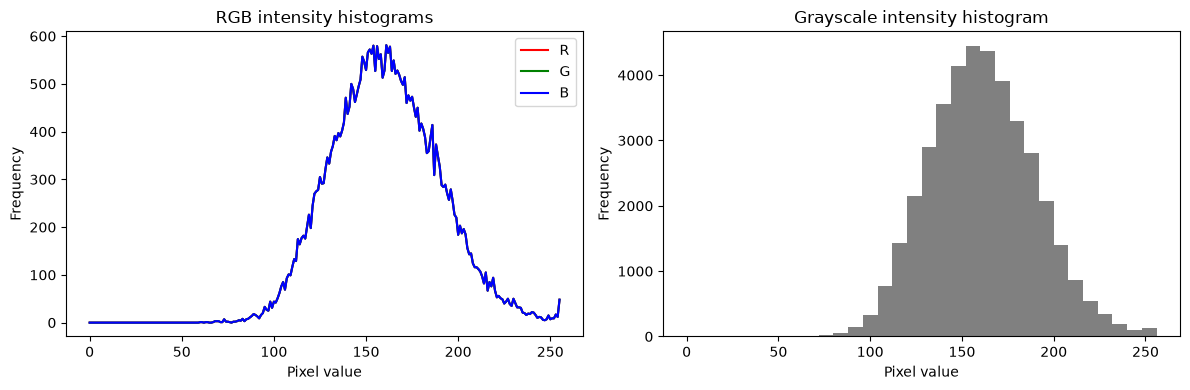

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for channel, color, name in zip(cv2.split(image_rgb), ["red", "green", "blue"], ["R", "G", "B"]):
    histogram = cv2.calcHist([channel], [0], None, [256], [0, 256]).ravel()
    axes[0].plot(histogram, color=color, label=name)
axes[0].set_title("RGB intensity histograms")
axes[0].set_xlabel("Pixel value")
axes[0].set_ylabel("Frequency")
axes[0].legend()
axes[1].hist(gray.ravel(), bins=32, range=(0, 256), color="gray")
axes[1].set_title("Grayscale intensity histogram")
axes[1].set_xlabel("Pixel value")
axes[1].set_ylabel("Frequency")
plt.tight_layout()
plt.savefig(OUTPUT / "histograms.png", dpi=150)
plt.show()


# Pixel Relationships and Image Operations


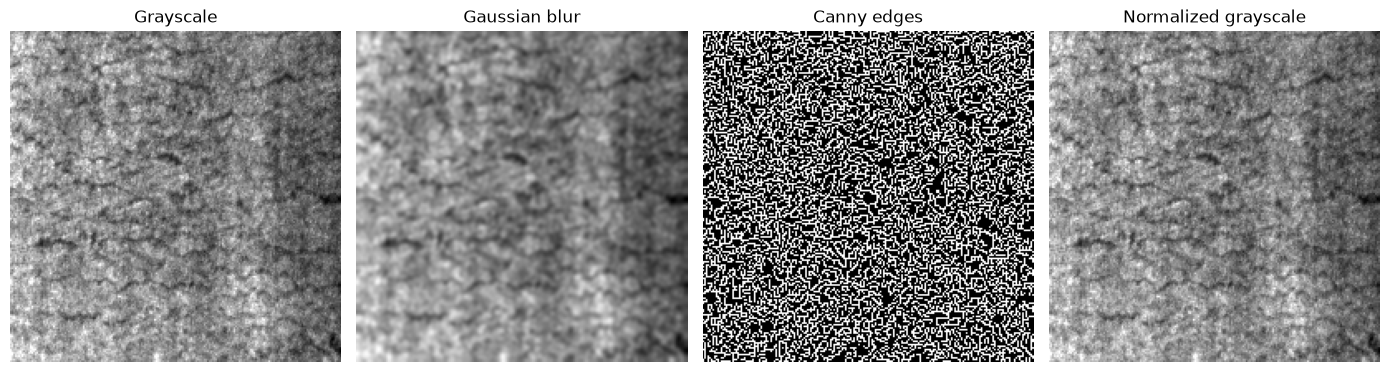

In [5]:
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
edges = cv2.Canny(gray, 50, 150)
normalized = cv2.normalize(gray, None, 0, 255, cv2.NORM_MINMAX)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, data, title in zip(axes, [gray, blurred, edges, normalized], ["Grayscale", "Gaussian blur", "Canny edges", "Normalized grayscale"]):
    ax.imshow(data, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT / "image_operations.png", dpi=150)
plt.show()


# Basic Image Statistics


In [8]:
statistics = {
    "file": sample_path.name,
    "height": image_bgr.shape[0],
    "width": image_bgr.shape[1],
    "channels": image_bgr.shape[2],
    "gray_min": float(gray.min()),
    "gray_max": float(gray.max()),
    "gray_mean": float(gray.mean()),
    "gray_std": float(gray.std()),
    "edge_density": float((edges > 0).mean())
}
print(statistics)
with open(OUTPUT / "basic_statistics.json", "w") as file:
    json.dump(statistics, file, indent=2)


{'file': 'crazing_1.jpg', 'height': 200, 'width': 200, 'channels': 3, 'gray_min': 60.0, 'gray_max': 255.0, 'gray_mean': 160.6365, 'gray_std': 28.498493254030116, 'edge_density': 0.378725}


# Review Findings


In [ ]:
print("- NEU-DET images are visually grayscale, so grayscale analytics are the main representation.")
print("- RGB channels have similar information; HSV and Lab are included for color-model comparison.")
print("- Histograms describe brightness and contrast, while edges describe local surface changes.")
print("- Gaussian blur reduces local noise and Canny edges provide a simple structural response.")
print("- These observations motivate grayscale, texture, edge, DCT, and morphology features in later notebooks.")
